# Ture and prediction

In [1]:
#  find the max R2 snapshot:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


def load_r2_list(json_path: str | Path, key: str | None = None) -> list[float]:
    """
    Load R2 values from a JSON file.

    Supports:
      1) A JSON list:            [0.51, 0.53, 0.49, ...]
      2) A JSON dict with key:   {"r2": [0.51, 0.53, ...]}  (set key="r2")
      3) A JSON dict of values:  {"run1": 0.51, "run2": 0.53, ...} (key=None)
    """
    json_path = Path(json_path)
    with json_path.open("r") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        r2 = obj
    elif isinstance(obj, dict):
        if key is not None:
            if key not in obj:
                raise KeyError(f"Key '{key}' not found. Available keys: {list(obj.keys())[:20]}")
            r2 = obj[key]
        else:
            # dict of scalar values -> take values in insertion order
            r2 = list(obj.values())
    else:
        raise TypeError(f"Unsupported JSON type: {type(obj)}")

    # Cast to float and validate
    out = []
    for i, v in enumerate(r2):
        try:
            out.append(float(v))
        except Exception as e:
            raise ValueError(f"Could not convert r2[{i}]={v!r} to float") from e

    return out


def plot_r2(r2: list[float], x: list[float] | None = None, title: str = "R² over index"):
    """
    Plot R2 vs index (default) or vs provided x.
    """
    if x is None:
        x = list(range(len(r2)))
        xlabel = "Index"
    else:
        if len(x) != len(r2):
            raise ValueError(f"x and r2 must have same length: {len(x)} vs {len(r2)}")
        xlabel = "x"

    plt.figure()
    plt.plot(x, r2, marker="o")
    plt.xlabel(xlabel)
    plt.ylabel("R²")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ------------------- Example usage -------------------
r2 = load_r2_list("../../../outputs/cfg_19/test_stats.json", key="image_r2_list")

print(len(r2))
print("index:", np.argmax(r2), "max value:", np.max(r2))

# we find that cfg_19 and cfg_17 has the max snapshot r2, 0.75 and 0.73


902
index: 298 max value: 0.751388369859943


In [3]:
# compare the npz data with data after data_loader
import torch
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]

y_true_path = "../../../outputs/cfg_19/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_19/test_y_pred.npy"
y_true = np.load(y_true_path)   # shape (N,1,H,W)
y_pred = np.load(y_pred_path)   # shape (N,1,H,W)

y_true_phys = y_true
y_pred_phys = y_pred

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cmocean.cm as cmo

def plot_snapshot_true_pred_error_paper(
    y_true_phys,
    y_pred_phys,
    XC_c,
    YC_c,
    t=5,
    units=r"W m$^{-2}$",
    pct_units="%",
    figsize=(17.5, 4.2),
    dpi=300,
    main_cmap=cmo.balance,
    err_cmap=cmo.balance,
    pct_cmap=cmo.balance,
    main_q=99,
    err_q=99,
    pct_q=99,
    eps=1e-12,
    savepath=None,
):
    """
    Paper-style plot for a signed variable:
    truth, prediction, error = prediction - truth,
    and percentage error = 100 * (prediction - truth) / truth.

    Parameters
    ----------
    eps : float
        Small threshold to avoid division by zero in percentage error.
        Points with |truth| < eps are set to NaN in the percentage error panel.
    """

    true_map = y_true_phys[t, 0] if y_true_phys.ndim == 4 else y_true_phys[t]
    pred_map = y_pred_phys[t, 0] if y_pred_phys.ndim == 4 else y_pred_phys[t]
    err_map  = pred_map - true_map

    true_map = np.asarray(true_map, dtype=float)
    pred_map = np.asarray(pred_map, dtype=float)
    err_map  = np.asarray(err_map, dtype=float)

    # percentage error: 100 * (pred - truth) / truth
    pct_err_map = np.full_like(err_map, np.nan, dtype=float)
    valid = np.isfinite(true_map) & np.isfinite(pred_map) & (np.abs(true_map) > eps)
    pct_err_map[valid] = 100.0 * err_map[valid] / true_map[valid]

    x = np.asarray(XC_c, dtype=float) / 1000.0
    y = np.asarray(YC_c, dtype=float) / 1000.0

    # shared symmetric color scale for signed truth/prediction
    main_pool = np.concatenate([
        true_map[np.isfinite(true_map)].ravel(),
        pred_map[np.isfinite(pred_map)].ravel()
    ])
    vabs_main = np.nanpercentile(np.abs(main_pool), main_q)
    norm_main = TwoSlopeNorm(vmin=-vabs_main, vcenter=0.0, vmax=vabs_main)

    # symmetric color scale for signed error
    vabs_err = np.nanpercentile(np.abs(err_map[np.isfinite(err_map)]), err_q)
    norm_err = TwoSlopeNorm(vmin=-vabs_err, vcenter=0.0, vmax=vabs_err)

    # symmetric color scale for percentage error
    norm_pct = TwoSlopeNorm(vmin=-500.0, vcenter=0.0, vmax=500.0)

    fig, axes = plt.subplots(1, 4, figsize=figsize, dpi=dpi)
    plt.subplots_adjust(left=0.055, right=0.96, bottom=0.14, top=0.86, wspace=0.20)

    panels = [
        (true_map, "Truth", norm_main, main_cmap, units),
        (pred_map, "Prediction", norm_main, main_cmap, units),
        (err_map, "Error (Prediction - Truth)", norm_err, err_cmap, units),
        (pct_err_map, "Percentage Error", norm_pct, pct_cmap, pct_units),
    ]

    ims = []
    for i, (ax, (field, ttl, norm, cmap, cbar_label)) in enumerate(zip(axes, panels)):
        im = ax.pcolormesh(
            x, y, field,
            shading="auto",
            cmap=cmap,
            norm=norm,
            rasterized=True,
        )
        ims.append(im)

        ax.set_title(ttl, fontsize=12)
        ax.set_aspect("equal")
        ax.set_xlabel("X (km)", fontsize=10)
        ax.tick_params(axis="both", labelsize=9)

        if i == 0:
            ax.set_ylabel("Y (km)", fontsize=10)
        else:
            ax.set_ylabel("")

        ax.text(
            0.02, 0.98, f"({chr(97+i)})",
            transform=ax.transAxes,
            ha="left", va="top",
            fontsize=11,
            fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.2),
        )

    # one shared colorbar for truth + prediction
    cbar_main = fig.colorbar(
        ims[0],
        ax=axes[:2],
        fraction=0.03,
        pad=0.02
    )
    cbar_main.set_label(units, fontsize=10)
    cbar_main.ax.tick_params(labelsize=9)

    # colorbar for absolute error
    cbar_err = fig.colorbar(
        ims[2],
        ax=axes[2],
        fraction=0.046,
        pad=0.02
    )
    cbar_err.set_label(units, fontsize=10)
    cbar_err.ax.tick_params(labelsize=9)

    # colorbar for percentage error
    cbar_pct = fig.colorbar(
        ims[3],
        ax=axes[3],
        fraction=0.046,
        pad=0.02
    )
    cbar_pct.set_label(pct_units, fontsize=10)
    cbar_pct.ax.tick_params(labelsize=9)

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")

    plt.show()

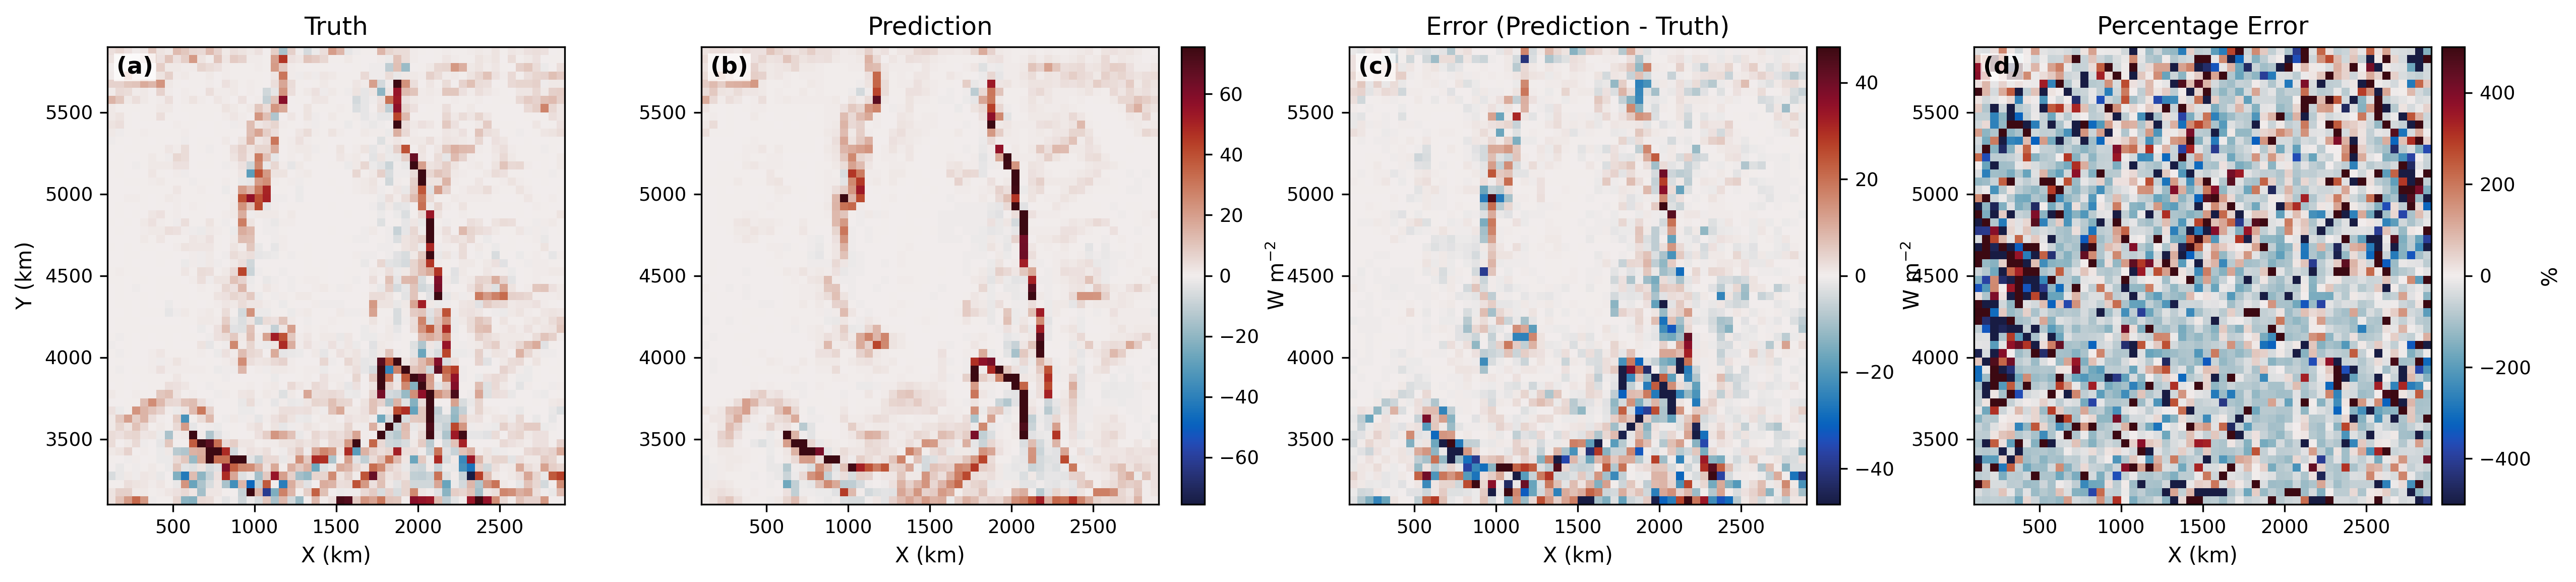

In [11]:
plot_snapshot_true_pred_error_paper(
    y_true_phys=y_true_phys,
    y_pred_phys=y_pred_phys,
    XC_c=XC_c[62:118,2:58],
    YC_c=YC_c[62:118,2:58],
    t=298,
    units=r"W m$^{-2}$",   # change if needed
    savepath="./snapshot_true_pred_error_t298.png"
)

# Top 10%

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cmo

def _robust_sym_vmax_from_both(a, b, q=0.99):
    """Symmetric vmax from robust quantile of |a| and |b| combined."""
    aa = np.asarray(a).ravel()
    bb = np.asarray(b).ravel()
    m = np.isfinite(aa); aa = aa[m]
    m = np.isfinite(bb); bb = bb[m]
    vals = np.concatenate([np.abs(aa), np.abs(bb)])
    vmax = np.nanquantile(vals, q)
    return float(vmax)

def top_percent_mask(arr2d, p=90):
    a = np.asarray(arr2d)
    m = np.isfinite(a)
    thr = np.nanpercentile(np.abs(a[m]), p)
    return (np.abs(a) >= thr) & m, thr

def plot_top_extremes_same_scale(
    y_true, y_pred,
    X=None, Y=None,
    p_front=90,         # top 10% => percentile 90
    q_color=0.99,       # robust color scale (99th percentile)
    err_q_color=0.99,   # robust error color scale
    title_prefix="Top 10% |y_true|"
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mask, thr = top_percent_mask(y_true, p=p_front)

    yt = np.where(mask, y_true, np.nan)
    yp = np.where(mask, y_pred, np.nan)
    err = np.where(mask, y_pred - y_true, np.nan)

    # --- SAME scale as the "normal plot": robust symmetric limits based on FULL fields (not masked)
    vmax = _robust_sym_vmax_from_both(y_true, y_pred, q=q_color)

    # error scale (robust on full error field)
    full_err = (y_pred - y_true)
    emax = float(np.nanquantile(np.abs(full_err[np.isfinite(full_err)]), err_q_color))

    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2), constrained_layout=True)

    def _plot(ax, Z, ttl, vmin=None, vmax=None):
        if X is None or Y is None:
            im = ax.imshow(Z, origin="lower", cmap=cmo.balance, vmin=vmin, vmax=vmax)
        else:
            im = ax.pcolormesh(X, Y, Z, shading="auto", cmap=cmo.balance, vmin=vmin, vmax=vmax)
        ax.set_title(ttl)
        ax.set_xlabel("x (m)" if X is not None else "")
        ax.set_ylabel("y (m)" if Y is not None else "")
        cb = fig.colorbar(im, ax=ax, pad=0.02, shrink=0.9)
        return im

    _plot(axes[0], yt, f"Truth (|y| ≥ P{p_front})", vmin=-vmax, vmax=vmax)
    _plot(axes[1], yp, "Prediction (masked)", vmin=-vmax, vmax=vmax)
    _plot(axes[2], err, "Error (Pred − Truth)", vmin=-emax, vmax=emax)

    fig.suptitle(
        f"{title_prefix}   |  Mask threshold = {thr:.3g}\n"
        f"Color scale: symmetric q={q_color:.2f} for Truth/Pred; q={err_q_color:.2f} for Error",
        y=1.04
    )
    plt.show()
    return {"mask_threshold": thr, "vmax_truth_pred": vmax, "emax_error": emax}

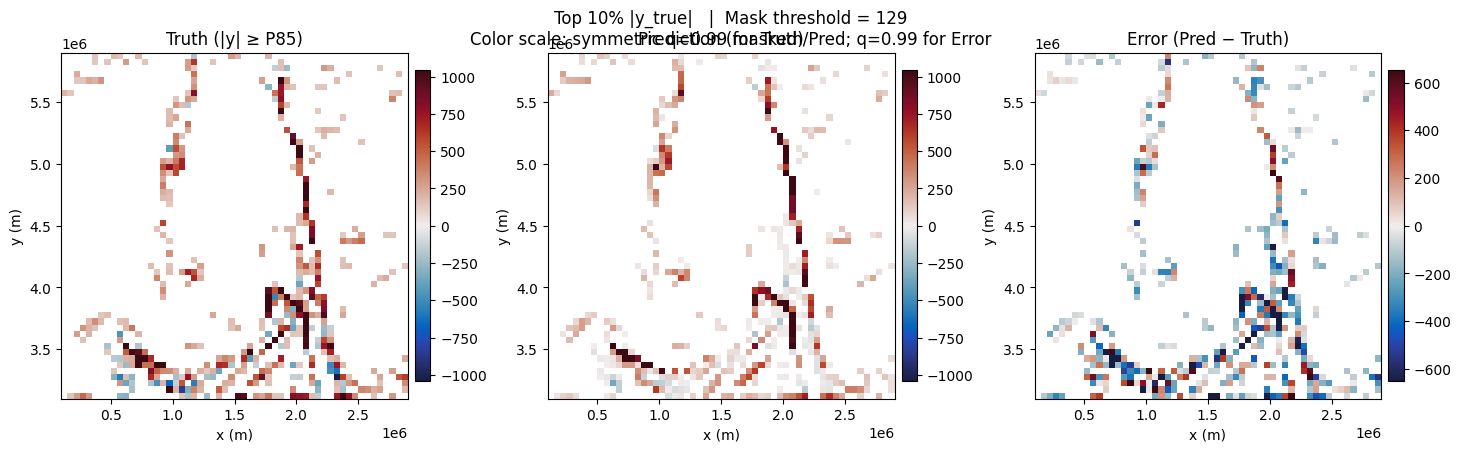

{'mask_threshold': 128.95297622680664, 'vmax_truth_pred': 1044.2855993652342, 'emax_error': 653.2720397949222}


In [22]:

stats = plot_top_extremes_same_scale(
    y_true_phys[298,0,:,:], y_pred_phys[298,0,:,:],
    X=XC_c[62:118,2:58], Y=YC_c[62:118,2:58],          # optional
    p_front=85,          # top 10%
    q_color=0.99,        # <- your request
    err_q_color=0.99
)
print(stats)

In [18]:
import numpy as np

def r2_masked(y_true_2d, y_pred_2d, mask, eps=1e-12):
    """
    R^2 computed only over pixels where mask==True.
    Baseline mean is computed over the same masked pixels (standard).
    """
    yt = np.asarray(y_true_2d)[mask].astype(np.float64)
    yp = np.asarray(y_pred_2d)[mask].astype(np.float64)

    m = np.isfinite(yt) & np.isfinite(yp)
    yt = yt[m]; yp = yp[m]
    if yt.size < 2:
        return np.nan

    sse = np.sum((yp - yt)**2)
    sst = np.sum((yt - yt.mean())**2)
    return 1.0 - sse/(sst + eps)

In [32]:
def top_percent_mask(arr2d, p=90):
    a = np.asarray(arr2d)
    m = np.isfinite(a)
    thr = np.nanpercentile(np.abs(a[m]), p)
    return (np.abs(a) >= thr) & m, thr

mask, thr = top_percent_mask(y_true_phys[298,0,:,:], p=87)   # top 10%+
r2_top10 = r2_masked(y_true_phys[298,0,:,:], y_pred_phys[298,0,:,:], mask)
print("Top 10% |y_true| R2 =", r2_top10, " threshold =", thr)

Top 10% |y_true| R2 = 0.7142678272413482  threshold = 149.93764343261714


In [21]:
valid = np.isfinite(y_true_phys[298,0,:,:]) & np.isfinite(y_true_phys[298,0,:,:])
bg_mask = valid & (~mask)

r2_bg = r2_masked(y_true_phys[298,0,:,:], y_pred_phys[298,0,:,:], bg_mask)
print("Background 90% R2 =", r2_bg)

Background 90% R2 = -0.2765346700581621


# check the bias and the misalignment

In [34]:
import numpy as np

def amplitude_bias_stats(y_true, y_pred):
    yt = np.asarray(y_true).ravel()
    yp = np.asarray(y_pred).ravel()
    m = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[m], yp[m]

    # linear fit yp ≈ a*yt + b
    A = np.vstack([yt, np.ones_like(yt)]).T
    a, b = np.linalg.lstsq(A, yp, rcond=None)[0]

    e = yp - yt
    corr_e_y = np.corrcoef(e, yt)[0, 1]
    return {"slope_a": a, "intercept_b": b, "corr(error, truth)": corr_e_y}

In [35]:
def r2_flat(y_true, y_pred, eps=1e-12):
    yt = np.asarray(y_true).ravel()
    yp = np.asarray(y_pred).ravel()
    m = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[m], yp[m]
    sse = np.sum((yp - yt)**2)
    sst = np.sum((yt - yt.mean())**2)
    return 1.0 - sse/(sst + eps)

def shift2d(arr, dj, di):
    # shift in (j,i); uses roll (periodic). If you prefer non-periodic, use padding+crop.
    return np.roll(np.roll(arr, dj, axis=0), di, axis=1)

def best_shift_r2(y_true, y_pred, max_shift=3):
    base = r2_flat(y_true, y_pred)
    best = base
    best_shift = (0, 0)
    for dj in range(-max_shift, max_shift+1):
        for di in range(-max_shift, max_shift+1):
            yp_s = shift2d(y_pred, dj, di)
            r2 = r2_flat(y_true, yp_s)
            if r2 > best:
                best = r2
                best_shift = (dj, di)
    return {"r2_base": base, "r2_best_shift": best, "best_shift_(dj,di)": best_shift,
            "delta_r2": best - base}

In [38]:
# --- 1) magnitude bias stats (slope/intercept + corr(error, truth)) ---
bias = amplitude_bias_stats(y_true_phys[298,0,:,:], y_pred_phys[298,0,:,:])
print("Amplitude/bias diagnostics:")
for k, v in bias.items():
    print(f"  {k}: {v}")

# --- 2) misalignment test (best small shift) ---
shift_info = best_shift_r2(y_true_phys[298,0,:,:], y_pred_phys[298,0,:,:], max_shift=6)
print("\nMisalignment diagnostics:")
for k, v in shift_info.items():
    print(f"  {k}: {v}")

Amplitude/bias diagnostics:
  slope_a: 0.639082670211792
  intercept_b: 13.459905624389648
  corr(error, truth): -0.725884338698507

Misalignment diagnostics:
  r2_base: 0.7513883744734813
  r2_best_shift: 0.7513883744734813
  best_shift_(dj,di): (0, 0)
  delta_r2: 0.0
